# A Bayesian CNN: asking a network several times

Average a Bayesian CNN's repeated predictions, and use their disagreement to flag unfamiliar inputs.

A Bayesian network learns a **distribution** over its weights instead of a single value. Each
prediction samples new weights, like asking a slightly different expert. When the experts agree,
the network is sure; when they disagree, it is not. Two benefits follow:

- **Averaging** several predictions is usually more accurate than any single one.
- The **disagreement** between them measures what the network does not know, and flags inputs
  unlike the training data.

Here, a Bayesian CNN learns Fashion-MNIST and is then shown MNIST digits.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) clothing images for training
and testing, and [MNIST](https://yann.lecun.com/exdb/mnist/) digits as unfamiliar inputs.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
(_, _), (x_digits, _) = keras.datasets.mnist.load_data()
x_train, x_test, x_digits = (images[..., None].astype("float32") / 255 for images in (x_train, x_test, x_digits))

## A Bayesian CNN

`Conv2DFlipout` and `DenseFlipout` are the Bayesian versions of `Conv2D` and `Dense`. Training
fits the data while keeping each weight distribution close to a prior; `kl_weight` (the standard
choice is `1 / number of training examples`) sets how much the prior counts.

In [3]:
kl_weight = 1.0 / len(x_train)
model = keras.Sequential(
    [
        keras.Input((28, 28, 1)),
        keras_proba.layers.Conv2DFlipout(16, 3, padding="same", activation="relu", kl_weight=kl_weight),
        keras.layers.MaxPooling2D(),
        keras_proba.layers.Conv2DFlipout(32, 3, padding="same", activation="relu", kl_weight=kl_weight),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras_proba.layers.DenseFlipout(128, activation="relu", kl_weight=kl_weight),
        keras_proba.layers.DenseFlipout(10, kl_weight=kl_weight),
    ]
)
model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
model.fit(x_train, y_train, epochs=5, batch_size=128, verbose=0)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Ask the network 20 times

Every `predict` call samples new weights. We keep all 20 predicted class distributions.

In [4]:
def predict_samples(x, num_samples=20):
    logits = [model.predict(x, batch_size=512, verbose=0) for _ in range(num_samples)]
    return np.stack([keras.ops.convert_to_numpy(keras.ops.softmax(l)) for l in logits])  # (samples, images, classes)


samples_test, samples_digits = predict_samples(x_test), predict_samples(x_digits)
single = (samples_test[0].argmax(-1) == y_test).mean()
averaged = (samples_test.mean(0).argmax(-1) == y_test).mean()
print(f"Accuracy: one prediction {single:.1%}, average of 20 predictions {averaged:.1%}")

Accuracy: one prediction 87.5%, average of 20 predictions 88.9%


## Measure the disagreement

The **mutual information** between the predictions and the weights measures how much the 20
predictions disagree: the entropy of their average minus their average entropy. It is near zero
when all samples predict the same thing, and large when they contradict each other.

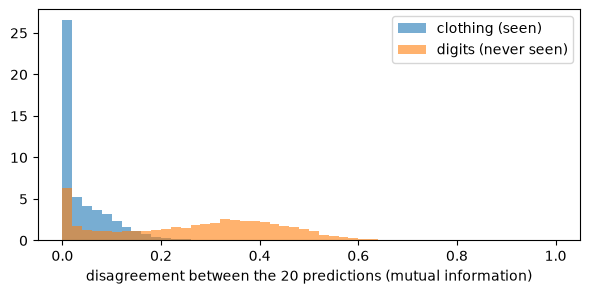

Disagreement separates digits from clothing with AUROC 0.874 (0.5 = chance)


In [5]:
def entropy(p):
    return -np.sum(p * np.log(p + 1e-12), axis=-1)


def mutual_information(samples):
    return entropy(samples.mean(0)) - entropy(samples).mean(0)


plt.figure(figsize=(7, 3))
plt.hist(mutual_information(samples_test), bins=50, range=(0, 1), alpha=0.6, density=True, label="clothing (seen)")
plt.hist(mutual_information(samples_digits), bins=50, range=(0, 1), alpha=0.6, density=True, label="digits (never seen)")
plt.xlabel("disagreement between the 20 predictions (mutual information)")
plt.legend()
plt.show()


def auroc(familiar, unfamiliar):
    ranks = np.concatenate([familiar, unfamiliar]).argsort().argsort() + 1
    n, m = len(familiar), len(unfamiliar)
    return (ranks[n:].sum() - m * (m + 1) / 2) / (n * m)


print(f"Disagreement separates digits from clothing with AUROC {auroc(mutual_information(samples_test), mutual_information(samples_digits)):.3f} (0.5 = chance)")

## What we learned

- Bayesian layers are drop-in replacements for `Conv2D` and `Dense`; every prediction samples
  new weights.
- Averaging repeated predictions improves accuracy, and their disagreement flags inputs the
  network does not know.
- The cost is several forward passes per prediction. [SNGP](https://anas-rz.github.io/keras-proba/examples/sngp_ood_detection/)
  detects unfamiliar inputs in a single pass.